In [2]:
### Step 1: Import Libaries

import numpy as np
import matplotlib.pyplot as plt


In [4]:
### Step 2: Create a small image and a filter

image = np.array([[1,0,1,0,1,0],[0,1,1,0,1,1],[1,0,1,0,1,0],[1,0,1,1,1,0],[0,1,1,0,1,1],[1,0,1,0,1,0],])

kernel = np.array([[1,0,1],[0,1,0],[1,0,1],
                   ])
print(image)

[[1 0 1 0 1 0]
 [0 1 1 0 1 1]
 [1 0 1 0 1 0]
 [1 0 1 1 1 0]
 [0 1 1 0 1 1]
 [1 0 1 0 1 0]]


In [6]:
### Step 3: Slide the filter to get a feature map

def convolve(image, kernel):
  k = kernel.shape[0]
  out_size = image.shape[0] - k +1
  result = np.zeros((out_size, out_size))
  for i in range(out_size):
    for j in range(out_size):
      patch = image [i:i+k, j:j+k]
      result[1, j] = np.sum(patch * kernel)
    return result

feature_map = convolve(image, kernel)
print(feature_map)

[[0. 0. 0. 0.]
 [5. 1. 4. 1.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]


In [7]:
### Step 4: Shrink It with max pooling

def max_pool(feature_map, size=2):
  out_size = feature_map.shape[0] // size
  result = np.zeros((out_size, out_size))
  for i in range(out_size):
    for j in range(out_size):
      window = feature_map [i*size:(i+1)*size, j*size:(j+1)*size]
      result[i,j] = np.max(window)
  return result

pooled = max_pool(feature_map,size=2)
print(pooled)

[[5. 4.]
 [0. 0.]]


In [8]:
### Step 5: Flatten the pooled Map

flattened = pooled.flatten()
print(flattened)

[5. 4. 0. 0.]


In [13]:
### Step 6: Build the same layers with Keras

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D,Flatten,Dense

model = Sequential()
model.add(Input(shape=(6,6,1)))
model.add(Conv2D(4, kernel_size=(3,3), activation='relu'))
print('after Conv2D:', model.output_shape)

after Conv2D: (None, 4, 4, 4)


In [14]:
### Step 7: Add pooling, Flattening, and a Dense Layer
model.add(MaxPooling2D(pool_size=(2,2)))
print("after MaxPooling2D:", model.output_shape)

model.add(Flatten())
print('after Flatten:',model.output_shape)

after MaxPooling2D: (None, 2, 2, 4)
after Flatten: (None, 16)


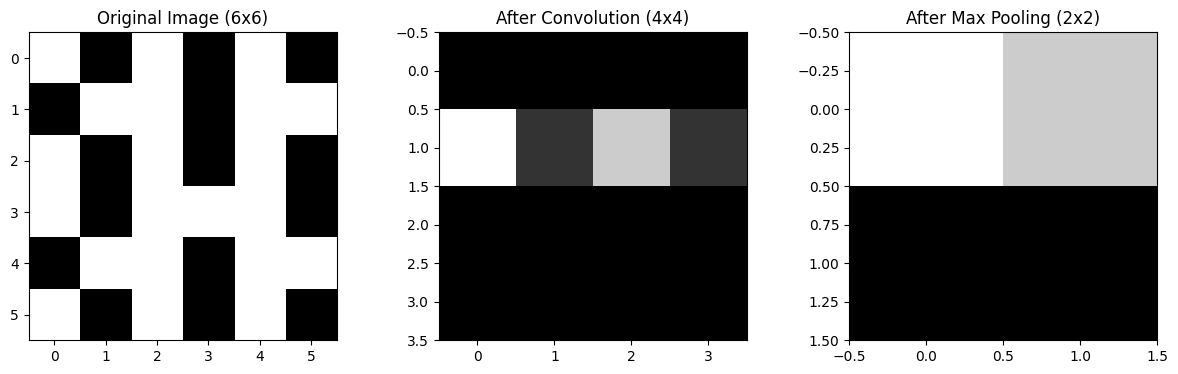

In [16]:
### Step 8: Visualize Every Stage

fig, axes = plt.subplots(1,3, figsize=(15,4))

axes[0].imshow(image,cmap='gray')
axes[0].set_title("Original Image (6x6)")

axes[1].imshow(feature_map,cmap ="gray")
axes[1].set_title("After Convolution (4x4)")

axes[2].imshow(pooled,cmap='gray')
axes[2].set_title('After Max Pooling (2x2)')

plt.show()